<a href="https://colab.research.google.com/github/vangchibinh/-ecowrap/blob/main/BAITHUCHANH1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

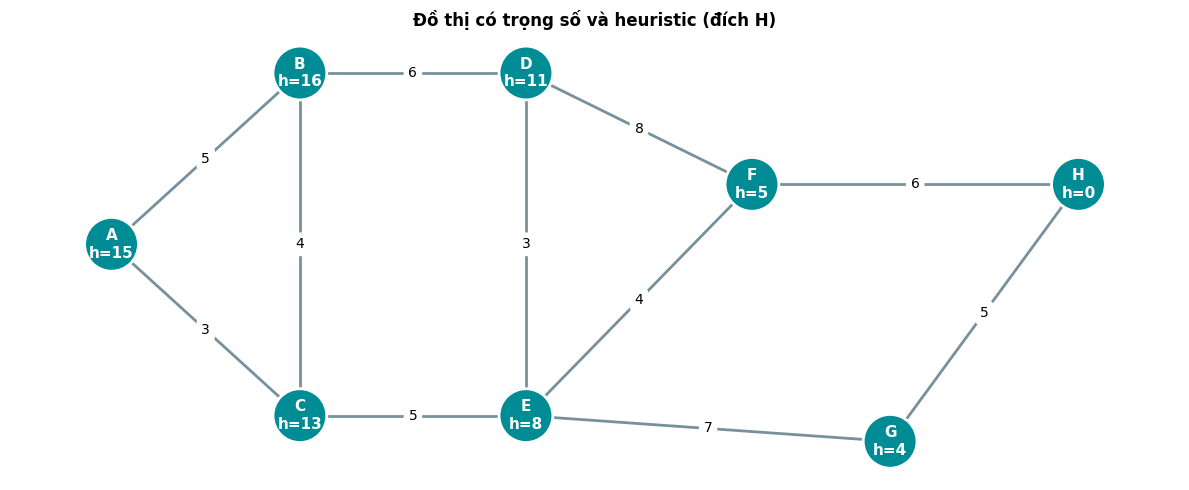

In [33]:
"""
# GIẢI THÍCH PHẦN KHỞI TẠO ĐỒ THỊ VÀ HÌNH ẢNH HÓA

Đoạn code bên dưới thực hiện các nhiệm vụ sau:
1. Định nghĩa danh sách các cạnh (`edges`) nối giữa các đỉnh kèm theo trọng số (khoảng cách thực tế giữa các đỉnh).
2. Định nghĩa hàm heuristic (`heuristic`) đại diện cho khoảng cách ước lượng (chim bay) từ mỗi đỉnh đến đích H.
3. Khởi tạo danh sách kề (`adjacency`) từ danh sách các cạnh để các thuật toán duyệt đồ thị (BFS, DFS, A*) hoạt động.
4. Sử dụng thư viện `networkx` để khởi tạo cấu trúc đồ thị vô hướng `G`.
5. Xác định tọa độ vẽ đồ thị (`pos`) giúp biểu diễn trực quan, rõ ràng các đỉnh và cạnh trên mặt phẳng.
6. Định nghĩa hàm `draw_graph` để trực quan hóa trạng thái đồ thị qua từng bước tìm kiếm:
   - Đỉnh đang xét (màu Cam)
   - Đỉnh đã phát hiện/mở rộng (màu Xanh nhạt)
   - Đỉnh nằm trong danh sách chờ duyệt (màu Vàng)
   - Đường đi cuối cùng tìm thấy (màu Xanh lá và nét đậm)
"""

import networkx as nx
import matplotlib.pyplot as plt
from collections import deque
from IPython.display import display, clear_output
import ipywidgets as widgets

# Danh sách cạnh: (đỉnh 1, đỉnh 2, trọng số)
edges = [
    ('A', 'B', 5), ('A', 'C', 3), ('B', 'C', 4),
    ('B', 'D', 6), ('C', 'E', 5), ('D', 'E', 3),
    ('D', 'F', 8), ('E', 'F', 4), ('E', 'G', 7),
    ('F', 'H', 6), ('G', 'H', 5),
]
heuristic = {'A': 15, 'B': 16, 'C': 13, 'D': 11,
             'E': 8, 'F': 5, 'G': 4, 'H': 0}

# Thứ tự kề cố định giúp bảng vết luôn nhất quán
adjacency = {node: [] for node in heuristic}
for u, v, w in edges:
    adjacency[u].append(v)
    adjacency[v].append(u)

G = nx.Graph()
G.add_weighted_edges_from(edges)
pos = {
    'A': (0, 1), 'B': (1.5, 2), 'C': (1.5, 0),
    'D': (3.3, 2), 'E': (3.3, 0), 'F': (5.1, 1.35),
    'G': (6.2, -0.15), 'H': (7.7, 1.35)
}

def draw_graph(ax, current=None, visited=None, queue=None, path=None,
               title='Đồ thị', show_heuristic=True):
    visited = set() if visited is None else set(visited)
    queue = [] if queue is None else list(queue)
    path = [] if path is None else list(path)
    path_edges = {frozenset((path[i], path[i+1])) for i in range(len(path)-1)}

    colors = []
    for node in G.nodes():
        if node == current:
            colors.append('#FF9800')
        elif node in path:
            colors.append('#00C853')
        elif node in visited:
            colors.append('#90CAF9')
        elif node in queue:
            colors.append('#FFF176')
        else:
            colors.append('#008C95')

    edge_colors = ['#E53935' if frozenset(e) in path_edges else '#78909C'
                   for e in G.edges()]
    edge_widths = [3.5 if frozenset(e) in path_edges else 2 for e in G.edges()]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=edge_widths)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=1500,
                           edgecolors='white', linewidths=2)

    labels = {n: f'{n}\nh={heuristic[n]}' if show_heuristic else n for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, ax=ax, labels=labels, font_size=11,
                            font_weight='bold', font_color='white')
    nx.draw_networkx_edge_labels(G, pos, ax=ax,
                                 edge_labels={(u, v): w for u, v, w in edges},
                                 font_size=10, rotate=False)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

fig, ax = plt.subplots(figsize=(12, 5))
draw_graph(ax, title='Đồ thị có trọng số và heuristic (đích H)')
plt.tight_layout()
plt.show()

In [34]:
def bfs_with_steps(graph, start, goal):
    if start not in graph or goal not in graph:
        raise ValueError('Đỉnh bắt đầu hoặc đích không có trong đồ thị.')
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    steps = []

    while queue:
        current = queue.popleft()
        newly_discovered = []
        if current != goal:
            for neighbor in graph[current]:
                if neighbor not in visited:
                    visited.add(neighbor)
                    parent[neighbor] = current
                    queue.append(neighbor)
                    newly_discovered.append(neighbor)

        steps.append({
            'current': current, 'queue': list(queue), 'visited': set(visited),
            'parent': dict(parent), 'newly_discovered': newly_discovered,
            'found': current == goal
        })
        if current == goal:
            break

    path = []
    if goal in parent:
        node = goal
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    return path, steps

start_node, goal_node = 'A', 'H'
path, steps = bfs_with_steps(adjacency, start_node, goal_node)
print('Đỉnh bắt đầu:', start_node)
print('Đỉnh đích:', goal_node)
print('Số bước xử lý:', len(steps))
print('Đường đi BFS:', ' → '.join(path))
print('Số cạnh:', len(path) - 1)
print('Tổng trọng số của đường BFS:', sum(G[u][v]['weight'] for u, v in zip(path, path[1:])))

Đỉnh bắt đầu: A
Đỉnh đích: H
Số bước xử lý: 8
Đường đi BFS: A → B → D → F → H
Số cạnh: 4
Tổng trọng số của đường BFS: 25


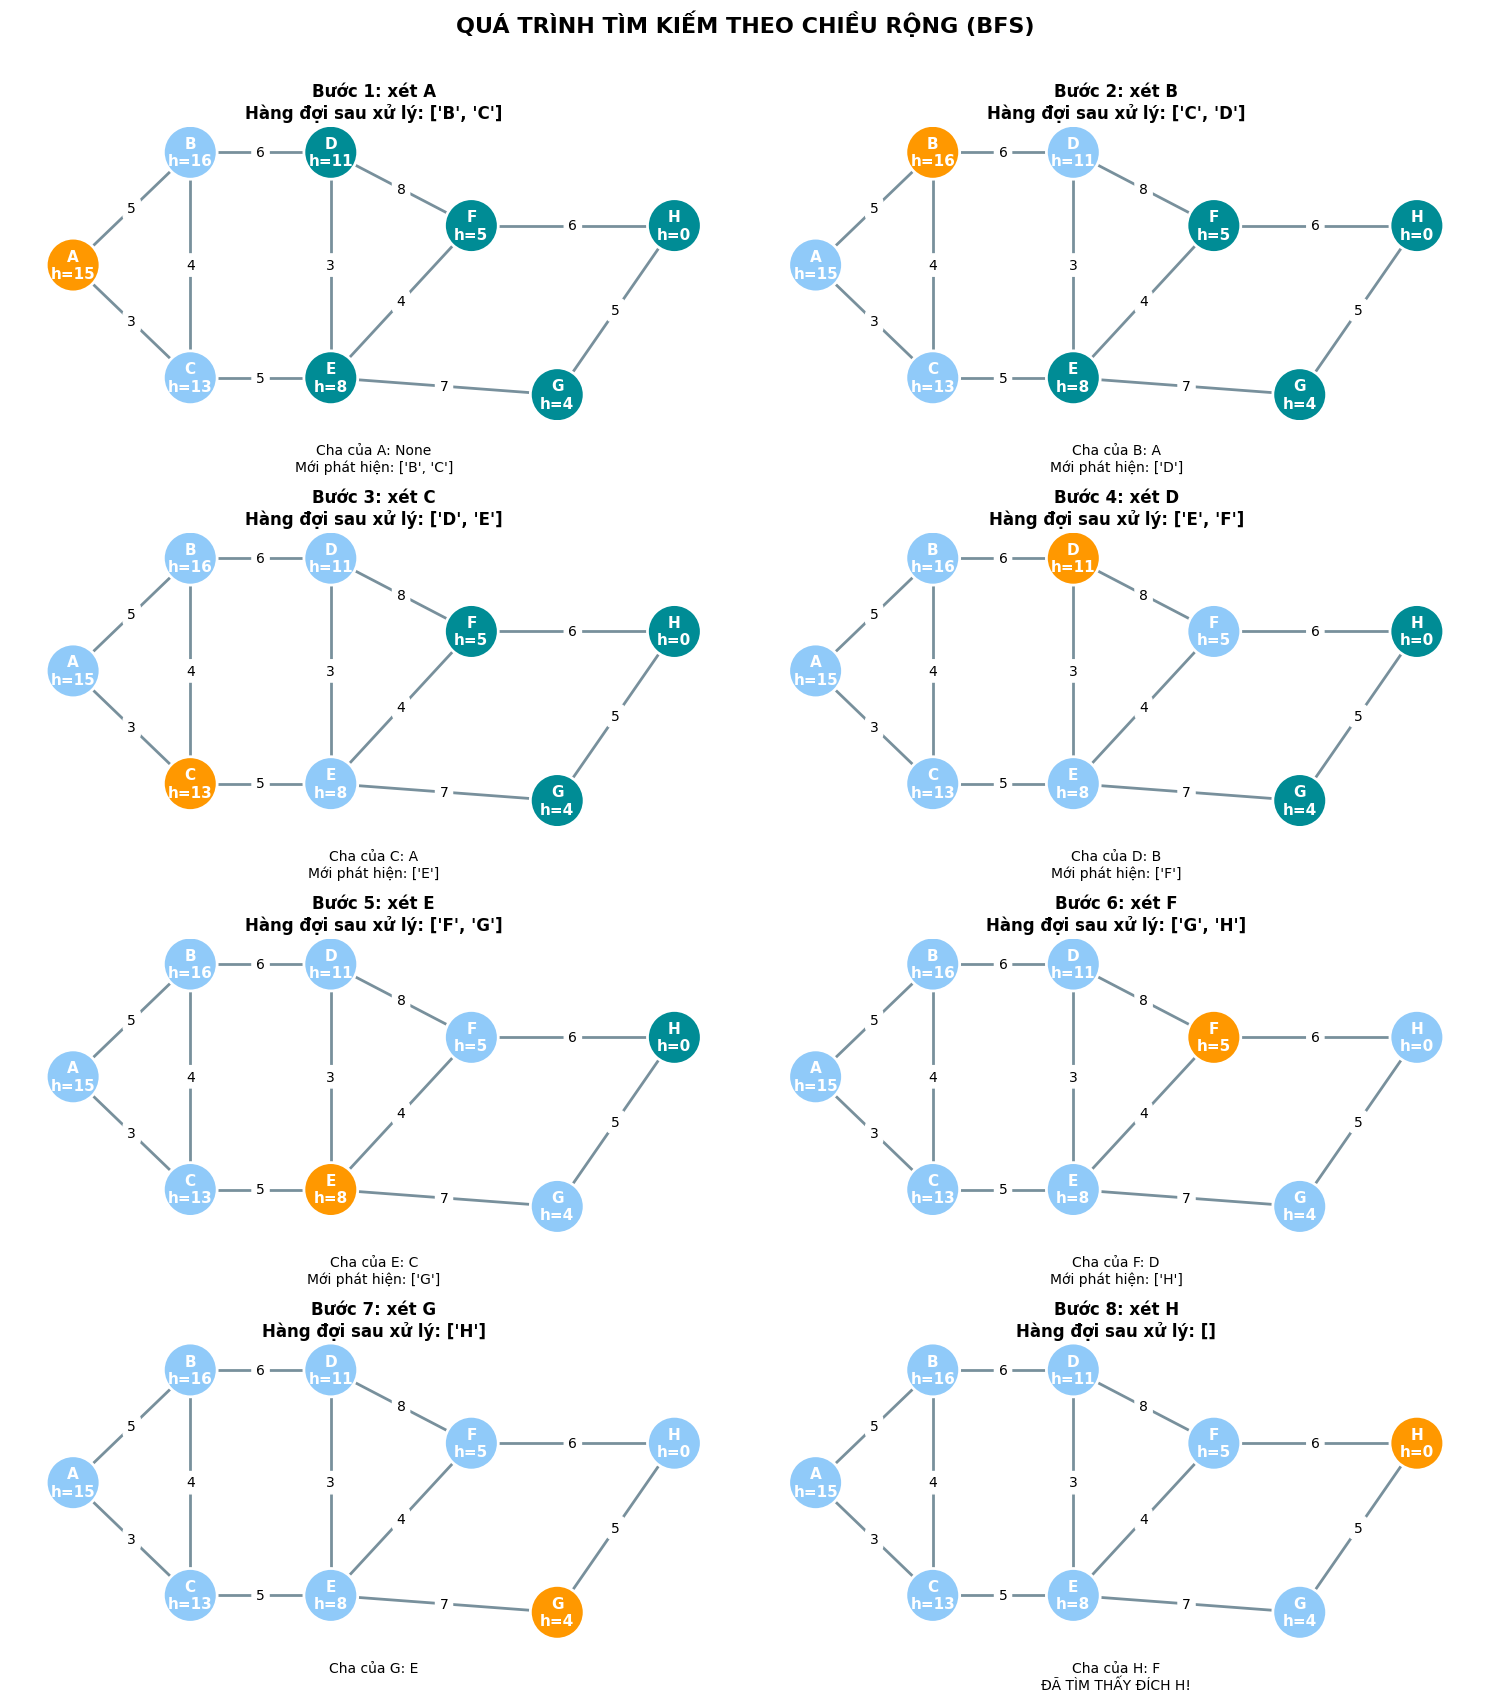

In [35]:
n_steps = len(steps)
ncols = 2
nrows = (n_steps + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.2 * nrows))
axes = axes.flatten()

for i, step in enumerate(steps):
    title = (f"Bước {i + 1}: xét {step['current']}\n"
             f"Hàng đợi sau xử lý: {step['queue']}")
    draw_graph(axes[i], current=step['current'], visited=step['visited'],
               queue=step['queue'], title=title)
    info = f"Cha của {step['current']}: {step['parent'].get(step['current'])}"
    if step['newly_discovered']:
        info += f"\nMới phát hiện: {step['newly_discovered']}"
    if step['found']:
        info += '\nĐÃ TÌM THẤY ĐÍCH H!'
    axes[i].text(0.5, -0.08, info, transform=axes[i].transAxes,
                 ha='center', va='top', fontsize=10)

for i in range(n_steps, len(axes)):
    axes[i].axis('off')
plt.suptitle('QUÁ TRÌNH TÌM KIẾM THEO CHIỀU RỘNG (BFS)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [36]:
print('=' * 88)
print(f"{'BƯỚC':<8}{'ĐỈNH XÉT':<12}{'ĐỈNH MỚI':<20}{'HÀNG ĐỢI SAU XỬ LÝ':<28}{'CHA'}")
print('=' * 88)
for i, step in enumerate(steps, start=1):
    current = step['current']
    print(f"{i:<8}{current:<12}{str(step['newly_discovered']):<20}"
          f"{str(step['queue']):<28}{step['parent'].get(current)}")
print('=' * 88)
print('Đường đi BFS:', ' → '.join(path))

BƯỚC    ĐỈNH XÉT    ĐỈNH MỚI            HÀNG ĐỢI SAU XỬ LÝ          CHA
1       A           ['B', 'C']          ['B', 'C']                  None
2       B           ['D']               ['C', 'D']                  A
3       C           ['E']               ['D', 'E']                  A
4       D           ['F']               ['E', 'F']                  B
5       E           ['G']               ['F', 'G']                  C
6       F           ['H']               ['G', 'H']                  D
7       G           []                  ['H']                       E
8       H           []                  []                          F
Đường đi BFS: A → B → D → F → H


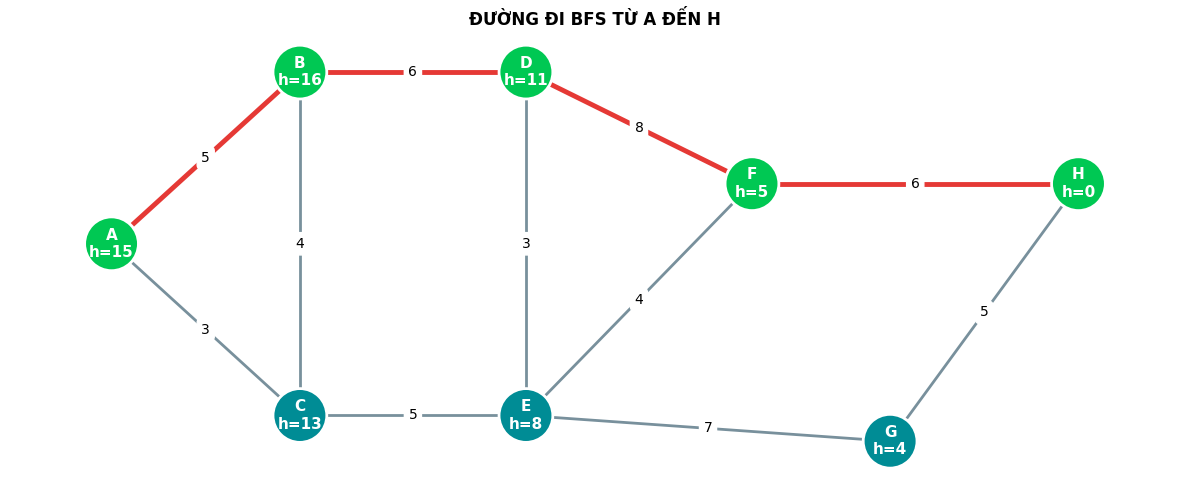

Đường đi BFS: A → B → D → F → H
Số cạnh: 4
Tổng trọng số (BFS không tối ưu trọng số): 25


In [37]:
fig, ax = plt.subplots(figsize=(12, 5))
draw_graph(ax, visited=set(path), path=path,
           title='ĐƯỜNG ĐI BFS TỪ A ĐẾN H')
plt.tight_layout()
plt.show()
print('Đường đi BFS:', ' → '.join(path))
print('Số cạnh:', len(path) - 1)
print('Tổng trọng số (BFS không tối ưu trọng số):',
      sum(G[u][v]['weight'] for u, v in zip(path, path[1:])))

In [38]:
# Tạo trạng thái bắt đầu và các trạng thái sau từng lần lấy đỉnh khỏi hàng đợi
simulation_steps = [{
    'current': None, 'queue': ['A'], 'visited': {'A'}, 'parent': {'A': None},
    'new_nodes': [], 'message': 'Khởi tạo: đưa A vào hàng đợi.'
}]
queue = deque(['A'])
visited_sim = {'A'}
parent_sim = {'A': None}

while queue:
    current = queue.popleft()
    new_nodes = []
    if current != 'H':
        for neighbor in adjacency[current]:
            if neighbor not in visited_sim:
                visited_sim.add(neighbor)
                parent_sim[neighbor] = current
                queue.append(neighbor)
                new_nodes.append(neighbor)
    simulation_steps.append({
        'current': current, 'queue': list(queue), 'visited': set(visited_sim),
        'parent': dict(parent_sim), 'new_nodes': new_nodes,
        'message': f"Xét {current}. Đỉnh mới: {new_nodes or 'không có'}."
    })
    if current == 'H':
        break

final_path = []
node = 'H'
while node is not None and node in parent_sim:
    final_path.append(node)
    node = parent_sim[node]
final_path.reverse()

step_index = 0
btn_prev = widgets.Button(description='◀ Bước trước', layout=widgets.Layout(width='125px'))
btn_next = widgets.Button(description='Bước tiếp ▶', button_style='primary', layout=widgets.Layout(width='125px'))
btn_play = widgets.Button(description='▶ Chạy tự động', button_style='success', layout=widgets.Layout(width='145px'))
btn_reset = widgets.Button(description='↺ Đặt lại', button_style='warning', layout=widgets.Layout(width='110px'))
step_slider = widgets.IntSlider(value=0, min=0, max=len(simulation_steps)-1, step=1,
                                description='Bước:', continuous_update=False,
                                layout=widgets.Layout(width='95%'))
output = widgets.Output()

_busy = False
def show_step(index):
    global step_index, _busy
    if _busy:
        return
    _busy = True
    try:
        step_index = max(0, min(index, len(simulation_steps)-1))
        s = simulation_steps[step_index]
        with output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(12, 5))
            found = s['current'] == 'H'
            draw_graph(ax, current=s['current'], visited=s['visited'], queue=s['queue'],
                       path=final_path if found else [],
                       title=f"BFS - Bước {step_index}/{len(simulation_steps)-1}")
            plt.tight_layout()
            plt.show()
            plt.close(fig)
            print('MÔ TẢ:', s['message'])
            print('Đỉnh đang xét:', s['current'] if s['current'] else 'Chưa xét')
            print('Hàng đợi:', s['queue'])
            print('Đã phát hiện:', sorted(s['visited']))
            print('Đỉnh mới:', s['new_nodes'])
            if found:
                print('ĐÃ TÌM THẤY H!')
                print('Đường đi:', ' → '.join(final_path))
        if step_slider.value != step_index:
            step_slider.value = step_index
    finally:
        _busy = False

def on_prev(_): show_step(step_index - 1)
def on_next(_): show_step(step_index + 1)
def on_reset(_): show_step(0)
def on_slider_change(change):
    if change['name'] == 'value' and not _busy:
        show_step(change['new'])

btn_prev.on_click(on_prev)
btn_next.on_click(on_next)
btn_reset.on_click(on_reset)
step_slider.observe(on_slider_change, names='value')

async def auto_play(_):
    import asyncio
    btn_play.disabled = True
    try:
        for i in range(step_index + 1, len(simulation_steps)):
            show_step(i)
            await asyncio.sleep(1.0)
    finally:
        btn_play.disabled = False
btn_play.on_click(auto_play)

display(widgets.VBox([
    widgets.HTML('<h3>Mô phỏng BFS: A → H</h3><p>Cam: đang xét | Xanh nhạt: đã phát hiện | Vàng: đang chờ | Xanh lá: đường đi cuối cùng. Trọng số cạnh được ghi trên hình.</p>'),
    widgets.HBox([btn_prev, btn_next, btn_play, btn_reset]), step_slider, output
]))
show_step(0)

In [39]:
def dfs_with_steps(graph, start, goal):
    if start not in graph or goal not in graph:
        raise ValueError('Đỉnh bắt đầu hoặc đích không có trong đồ thị.')
    stack = [start]
    visited = {start}
    parent = {start: None}
    steps = []

    while stack:
        current = stack.pop()
        newly_discovered = []
        if current != goal:
            for neighbor in reversed(graph[current]):
                if neighbor not in visited:
                    visited.add(neighbor)
                    parent[neighbor] = current
                    stack.append(neighbor)
                    newly_discovered.append(neighbor)
            newly_discovered.reverse()

        steps.append({
            'current': current,
            'queue': list(stack),  # danh sách này chính là ngăn xếp còn lại
            'visited': set(visited),
            'parent': dict(parent),
            'newly_discovered': newly_discovered,
            'found': current == goal
        })
        if current == goal:
            break

    path = []
    if goal in parent:
        node = goal
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    return path, steps

start_node, goal_node = 'A', 'H'
dfs_path, dfs_steps = dfs_with_steps(adjacency, start_node, goal_node)
print('Đỉnh bắt đầu:', start_node)
print('Đỉnh đích:', goal_node)
print('Số bước xử lý DFS:', len(dfs_steps))
print('Đường đi tìm được (DFS):', ' → '.join(dfs_path))
print('Số cạnh của đường đi:', len(dfs_path) - 1)
print('Tổng trọng số đường đi:', sum(G[u][v]['weight'] for u, v in zip(dfs_path, dfs_path[1:])))

Đỉnh bắt đầu: A
Đỉnh đích: H
Số bước xử lý DFS: 6
Đường đi tìm được (DFS): A → B → D → E → G → H
Số cạnh của đường đi: 5
Tổng trọng số đường đi: 26


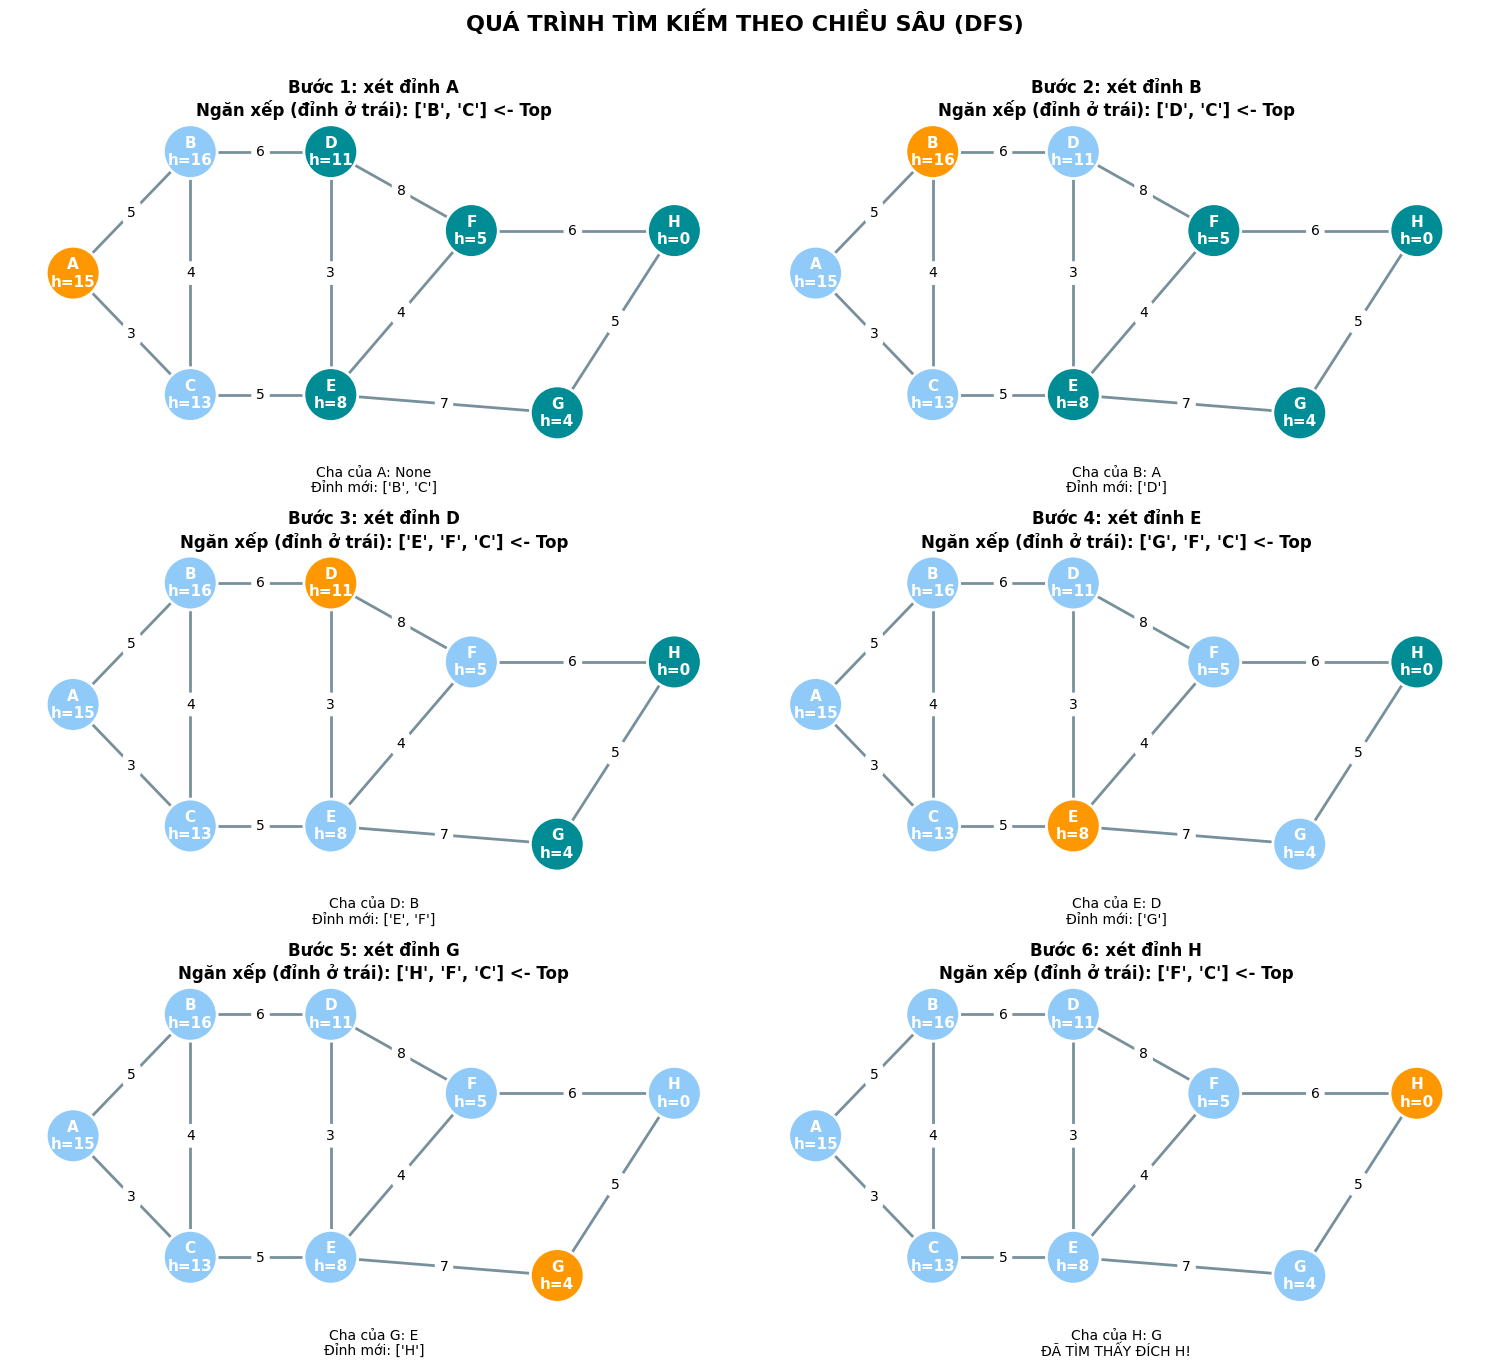

In [40]:
n_steps = len(dfs_steps)
ncols = 2
nrows = (n_steps + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = axes.flatten()

for i, step in enumerate(dfs_steps):
    current = step['current']
    stack_now = step['queue']
    stack_display = list(reversed(stack_now))
    title = (f"Bước {i + 1}: xét đỉnh {current}\n"
             f"Ngăn xếp (đỉnh ở trái): {stack_display} <- Top")
    draw_graph(axes[i], current=current, visited=step['visited'],
               queue=stack_now, title=title)
    info = f"Cha của {current}: {step['parent'].get(current)}"
    if step['newly_discovered']:
        info += f"\nĐỉnh mới: {step['newly_discovered']}"
    if step['found']:
        info += '\nĐÃ TÌM THẤY ĐÍCH H!'
    axes[i].text(0.5, -0.08, info, transform=axes[i].transAxes,
                 ha='center', va='top', fontsize=10)

for i in range(n_steps, len(axes)):
    axes[i].axis('off')
plt.suptitle('QUÁ TRÌNH TÌM KIẾM THEO CHIỀU SÂU (DFS)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [41]:
print('=' * 95)
print(f"{'BƯỚC':<8}{'ĐỈNH XÉT':<12}{'NGĂN XẾP (TOP TRÁI)':<38}{'ĐỈNH MỚI':<20}{'CHA'}")
print('=' * 95)
for i, step in enumerate(dfs_steps, start=1):
    stack_display = list(reversed(step['queue']))
    current = step['current']
    print(f"{i:<8}{current:<12}{str(stack_display):<38}"
          f"{str(step['newly_discovered']):<20}{step['parent'].get(current)}")
print('=' * 95)
print('Đường đi DFS:', ' → '.join(dfs_path))

BƯỚC    ĐỈNH XÉT    NGĂN XẾP (TOP TRÁI)                   ĐỈNH MỚI            CHA
1       A           ['B', 'C']                            ['B', 'C']          None
2       B           ['D', 'C']                            ['D']               A
3       D           ['E', 'F', 'C']                       ['E', 'F']          B
4       E           ['G', 'F', 'C']                       ['G']               D
5       G           ['H', 'F', 'C']                       ['H']               E
6       H           ['F', 'C']                            []                  G
Đường đi DFS: A → B → D → E → G → H


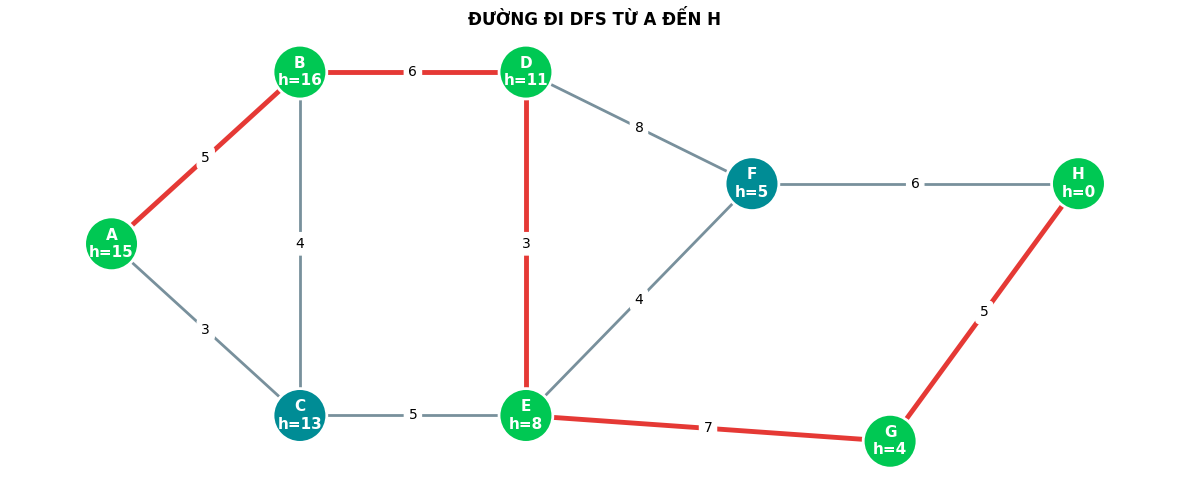

Đường đi DFS: A → B → D → E → G → H
Tổng số cạnh: 5
Tổng trọng số: 26


In [42]:
fig, ax = plt.subplots(figsize=(12, 5))
draw_graph(ax, visited=set(dfs_path), path=dfs_path,
           title='ĐƯỜNG ĐI DFS TỪ A ĐẾN H')
plt.tight_layout()
plt.show()
print('Đường đi DFS:', ' → '.join(dfs_path))
print('Tổng số cạnh:', len(dfs_path) - 1)
print('Tổng trọng số:', sum(G[u][v]['weight'] for u, v in zip(dfs_path, dfs_path[1:])))

In [43]:
# Dùng lại các bước đã ghi ở P7; thêm trạng thái khởi tạo để mô phỏng nút bấm.
dfs_simulation = [{
    'current': None, 'queue': ['A'], 'visited': {'A'}, 'parent': {'A': None},
    'newly_discovered': [], 'found': False,
    'message': 'Khởi tạo: đưa A vào ngăn xếp.'
}]
for s in dfs_steps:
    dfs_simulation.append({**s, 'message':
        f"Xét {s['current']}. Đỉnh mới: {s['newly_discovered'] or 'không có'}."})

dfs_index = 0
dfs_busy = False
dfs_prev = widgets.Button(description='◀ Bước trước', layout=widgets.Layout(width='125px'))
dfs_next = widgets.Button(description='Bước tiếp ▶', button_style='primary', layout=widgets.Layout(width='125px'))
dfs_play = widgets.Button(description='▶ Chạy tự động', button_style='success', layout=widgets.Layout(width='145px'))
dfs_reset = widgets.Button(description='↺ Đặt lại', button_style='warning', layout=widgets.Layout(width='110px'))
dfs_slider = widgets.IntSlider(value=0, min=0, max=len(dfs_simulation)-1, step=1,
                                description='Bước:', continuous_update=False,
                                layout=widgets.Layout(width='95%'))
dfs_output = widgets.Output()

def show_dfs_step(index):
    global dfs_index, dfs_busy
    if dfs_busy: return
    dfs_busy = True
    try:
        dfs_index = max(0, min(index, len(dfs_simulation)-1))
        s = dfs_simulation[dfs_index]
        stack_display = list(reversed(s['queue']))
        with dfs_output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(12, 5))
            draw_graph(ax, current=s['current'], visited=s['visited'], queue=s['queue'],
                       path=dfs_path if s['found'] else [],
                       title=f"DFS - Bước {dfs_index}/{len(dfs_simulation)-1}")
            plt.tight_layout(); plt.show(); plt.close(fig)
            print('MÔ TẢ:', s['message'])
            print('Đỉnh đang xét:', s['current'] if s['current'] else 'Chưa xét')
            print('Ngăn xếp (đỉnh trái là Top):', stack_display)
            print('Đã phát hiện:', sorted(s['visited']))
            print('Đỉnh mới:', s['newly_discovered'])
            if s['found']:
                print('ĐÃ TÌM THẤY H! Đường đi:', ' → '.join(dfs_path))
        if dfs_slider.value != dfs_index: dfs_slider.value = dfs_index
    finally:
        dfs_busy = False

def dfs_on_slider(change):
    if change['name'] == 'value' and not dfs_busy: show_dfs_step(change['new'])
def dfs_on_prev(_): show_dfs_step(dfs_index - 1)
def dfs_on_next(_): show_dfs_step(dfs_index + 1)
def dfs_on_reset(_): show_dfs_step(0)
async def dfs_auto_play(_):
    import asyncio
    dfs_play.disabled = True
    try:
        for i in range(dfs_index + 1, len(dfs_simulation)):
            show_dfs_step(i)
            await asyncio.sleep(1.0)
    finally:
        dfs_play.disabled = False

dfs_prev.on_click(dfs_on_prev); dfs_next.on_click(dfs_on_next)
dfs_reset.on_click(dfs_on_reset); dfs_play.on_click(dfs_auto_play)
dfs_slider.observe(dfs_on_slider, names='value')
display(widgets.VBox([
    widgets.HTML('<h3>Mô phỏng DFS: A → H</h3><p>Cam: đang xét | Xanh nhạt: đã phát hiện | Vàng: trong ngăn xếp | Xanh lá: đường đi cuối cùng.</p>'),
    widgets.HBox([dfs_prev, dfs_next, dfs_play, dfs_reset]), dfs_slider, dfs_output
]))
show_dfs_step(0)

In [44]:
import heapq

def astar_with_steps(graph, edge_list, h, start, goal):
    if start not in graph or goal not in graph:
        raise ValueError('Đỉnh bắt đầu hoặc đích không có trong đồ thị.')
    weights = {node: {} for node in graph}
    for u, v, w in edge_list:
        weights[u][v] = w
        weights[v][u] = w

    counter = 0
    heap = [(h[start], 0, counter, start)]  # (f, g, thứ tự thêm, đỉnh)
    open_nodes = {start}
    closed = set()
    parent = {start: None}
    g_score = {start: 0}
    steps = []

    while heap:
        f, g_cost, _, current = heapq.heappop(heap)
        if current in closed or g_cost != g_score.get(current):
            continue
        open_nodes.discard(current)
        closed.add(current)
        newly_discovered = []

        if current != goal:
            for neighbor in graph[current]:
                tentative_g = g_cost + weights[current][neighbor]
                if tentative_g < g_score.get(neighbor, float('inf')):
                    is_new = neighbor not in g_score
                    g_score[neighbor] = tentative_g
                    parent[neighbor] = current
                    counter += 1
                    heapq.heappush(heap, (tentative_g + h[neighbor], tentative_g, counter, neighbor))
                    open_nodes.add(neighbor)
                    if is_new:
                        newly_discovered.append(neighbor)

        open_display = sorted(open_nodes, key=lambda n: (g_score[n] + h[n], n))
        steps.append({
            'current': current, 'open': open_display, 'visited': set(closed),
            'parent': dict(parent), 'g_score': dict(g_score),
            'newly_discovered': newly_discovered, 'found': current == goal,
            'g': g_cost, 'h': h[current], 'f': g_cost + h[current]
        })
        if current == goal:
            break

    path = []
    if goal in parent:
        node = goal
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    return path, g_score.get(goal, float('inf')), steps

astar_path, astar_cost, astar_steps = astar_with_steps(
    adjacency, edges, heuristic, 'A', 'H'
)
print('Đỉnh bắt đầu: A | Đỉnh đích: H')
print('Số bước xử lý A*:', len(astar_steps))
print('Đường đi A*:', ' → '.join(astar_path))
print('Tổng trọng số:', astar_cost)

Đỉnh bắt đầu: A | Đỉnh đích: H
Số bước xử lý A*: 5
Đường đi A*: A → C → E → F → H
Tổng trọng số: 18


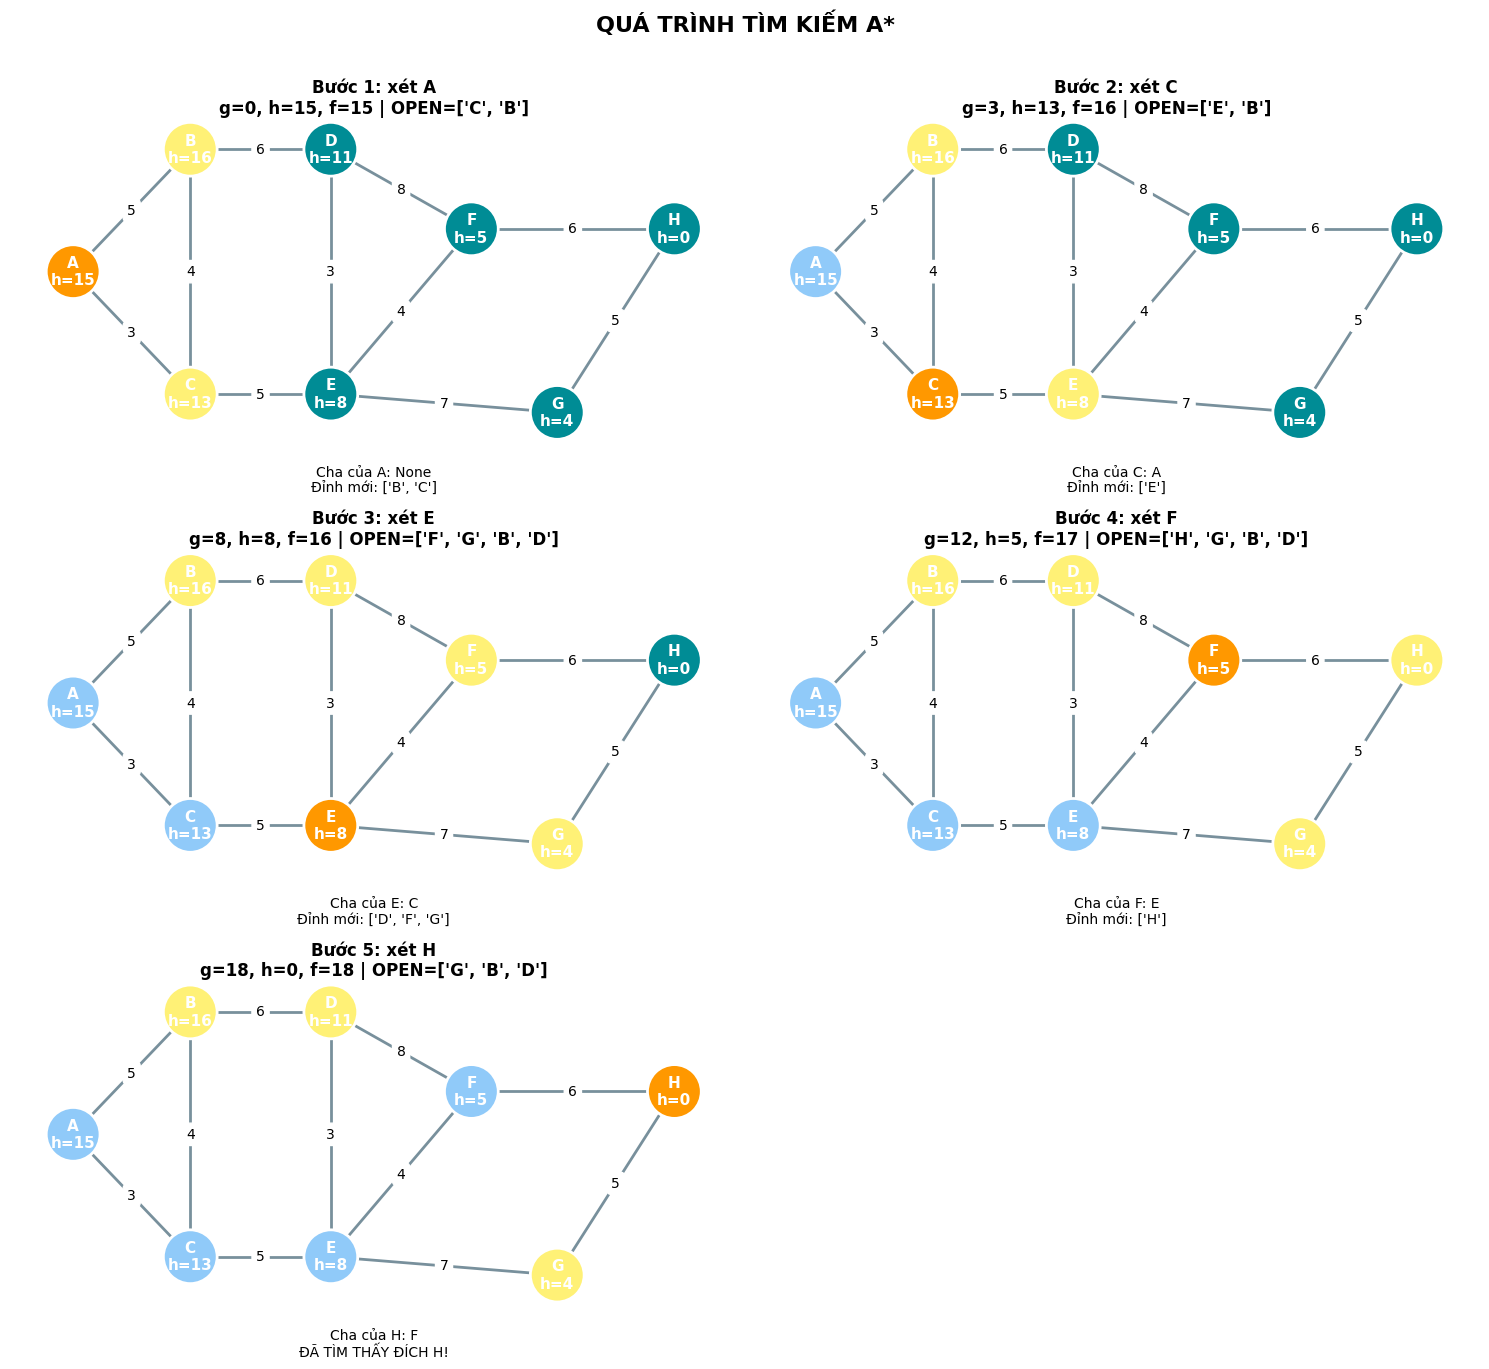

In [45]:
n_steps = len(astar_steps)
ncols = 2
nrows = (n_steps + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = axes.flatten()
for i, step in enumerate(astar_steps):
    current = step['current']
    title = (f"Bước {i + 1}: xét {current}\n"
             f"g={step['g']}, h={step['h']}, f={step['f']} | OPEN={step['open']}")
    draw_graph(axes[i], current=current, visited=step['visited'],
               queue=step['open'], title=title)
    info = f"Cha của {current}: {step['parent'].get(current)}"
    if step['newly_discovered']:
        info += f"\nĐỉnh mới: {step['newly_discovered']}"
    if step['found']:
        info += '\nĐÃ TÌM THẤY ĐÍCH H!'
    axes[i].text(0.5, -0.08, info, transform=axes[i].transAxes,
                 ha='center', va='top', fontsize=10)
for i in range(n_steps, len(axes)):
    axes[i].axis('off')
plt.suptitle('QUÁ TRÌNH TÌM KIẾM A*', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

In [46]:
print('=' * 104)
print(f"{'BƯỚC':<7}{'ĐỈNH XÉT':<12}{'g':<7}{'h':<7}{'f=g+h':<9}{'OPEN sau xử lý':<30}{'ĐỈNH MỚI'}")
print('=' * 104)
for i, step in enumerate(astar_steps, start=1):
    print(f"{i:<7}{step['current']:<12}{step['g']:<7}{step['h']:<7}{step['f']:<9}"
          f"{str(step['open']):<30}{step['newly_discovered']}")
print('=' * 104)
print('Đường đi A*:', ' → '.join(astar_path))
print('Tổng trọng số:', astar_cost)

BƯỚC   ĐỈNH XÉT    g      h      f=g+h    OPEN sau xử lý                ĐỈNH MỚI
1      A           0      15     15       ['C', 'B']                    ['B', 'C']
2      C           3      13     16       ['E', 'B']                    ['E']
3      E           8      8      16       ['F', 'G', 'B', 'D']          ['D', 'F', 'G']
4      F           12     5      17       ['H', 'G', 'B', 'D']          ['H']
5      H           18     0      18       ['G', 'B', 'D']               []
Đường đi A*: A → C → E → F → H
Tổng trọng số: 18


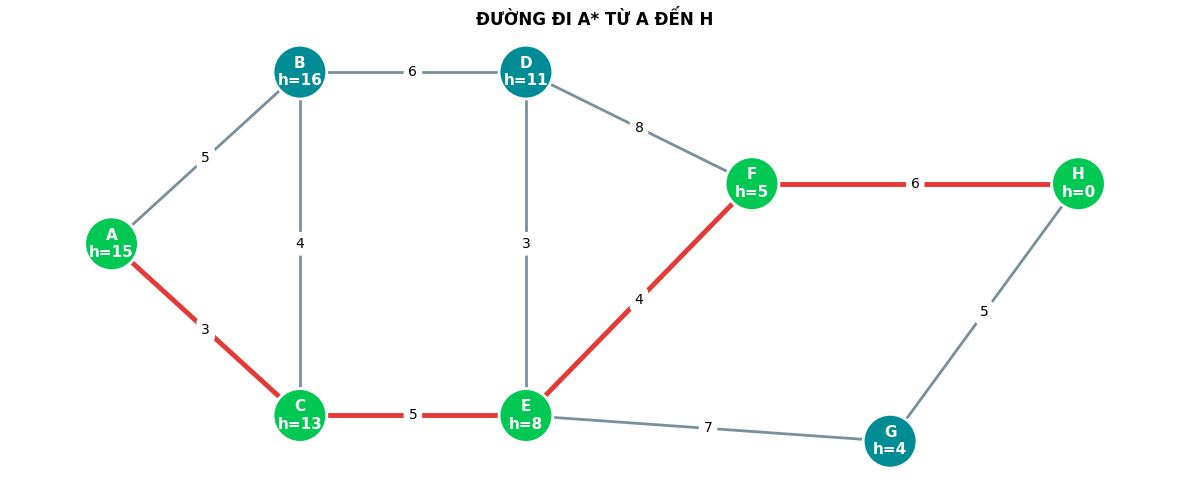

Đường đi tối ưu theo trọng số: A → C → E → F → H
Tổng trọng số: 18
Số cạnh: 4


In [47]:
fig, ax = plt.subplots(figsize=(12, 5))
draw_graph(ax, visited={s['current'] for s in astar_steps}, path=astar_path,
           title='ĐƯỜNG ĐI A* TỪ A ĐẾN H')
plt.tight_layout(); plt.show()
print('Đường đi tối ưu theo trọng số:', ' → '.join(astar_path))
print('Tổng trọng số:', astar_cost)
print('Số cạnh:', len(astar_path) - 1)

In [48]:
astar_simulation = [{
    'current': None, 'open': ['A'], 'visited': set(), 'parent': {'A': None},
    'g_score': {'A': 0}, 'newly_discovered': [], 'found': False,
    'g': 0, 'h': heuristic['A'], 'f': heuristic['A'],
    'message': 'Khởi tạo: đưa A vào OPEN với f(A)=g(A)+h(A).'
}]
for s in astar_steps:
    astar_simulation.append({**s, 'message':
        f"Xét {s['current']}: g={s['g']}, h={s['h']}, f={s['f']}. "
        f"Đỉnh mới: {s['newly_discovered'] or 'không có'}."})

astar_index = 0
astar_busy = False
astar_prev = widgets.Button(description='◀ Bước trước', layout=widgets.Layout(width='125px'))
astar_next = widgets.Button(description='Bước tiếp ▶', button_style='primary', layout=widgets.Layout(width='125px'))
astar_play = widgets.Button(description='▶ Chạy tự động', button_style='success', layout=widgets.Layout(width='145px'))
astar_reset = widgets.Button(description='↺ Đặt lại', button_style='warning', layout=widgets.Layout(width='110px'))
astar_slider = widgets.IntSlider(value=0, min=0, max=len(astar_simulation)-1, step=1,
                                  description='Bước:', continuous_update=False,
                                  layout=widgets.Layout(width='95%'))
astar_output = widgets.Output()

def show_astar_step(index):
    global astar_index, astar_busy
    if astar_busy: return
    astar_busy = True
    try:
        astar_index = max(0, min(index, len(astar_simulation)-1))
        s = astar_simulation[astar_index]
        with astar_output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(12, 5))
            draw_graph(ax, current=s['current'], visited=s['visited'], queue=s['open'],
                       path=astar_path if s['found'] else [],
                       title=f"A* - Bước {astar_index}/{len(astar_simulation)-1}")
            plt.tight_layout(); plt.show(); plt.close(fig)
            print('MÔ TẢ:', s['message'])
            print('Đỉnh đang xét:', s['current'] if s['current'] else 'Chưa xét')
            print('OPEN (ưu tiên f nhỏ):', s['open'])
            print('Đã mở rộng:', sorted(s['visited']))
            print('g-score:', s['g_score'])
            if s['found']:
                print('ĐÃ TÌM THẤY H!')
                print('Đường đi:', ' → '.join(astar_path))
                print('Tổng trọng số:', astar_cost)
        if astar_slider.value != astar_index: astar_slider.value = astar_index
    finally:
        astar_busy = False

def astar_on_slider(change):
    if change['name'] == 'value' and not astar_busy: show_astar_step(change['new'])
def astar_on_prev(_): show_astar_step(astar_index - 1)
def astar_on_next(_): show_astar_step(astar_index + 1)
def astar_on_reset(_): show_astar_step(0)
async def astar_auto_play(_):
    import asyncio
    astar_play.disabled = True
    try:
        for i in range(astar_index + 1, len(astar_simulation)):
            show_astar_step(i)
            await asyncio.sleep(1.0)
    finally:
        astar_play.disabled = False

astar_prev.on_click(astar_on_prev); astar_next.on_click(astar_on_next)
astar_reset.on_click(astar_on_reset); astar_play.on_click(astar_auto_play)
astar_slider.observe(astar_on_slider, names='value')
display(widgets.VBox([
    widgets.HTML('<h3>Mô phỏng A*: A → H</h3><p>Cam: đang xét | Xanh nhạt: đã mở rộng | Vàng: trong OPEN | Xanh lá: đường đi cuối cùng.</p>'),
    widgets.HBox([astar_prev, astar_next, astar_play, astar_reset]), astar_slider, astar_output
]))
show_astar_step(0)

```markdown
## Bài toán mới: Tìm kiếm trên Đồ thị có hướng (Directed Graph)

Chúng ta sẽ định nghĩa một đồ thị có hướng mới hướng tới đích là **G**. Mỗi đỉnh sẽ đi kèm với một giá trị Heuristic $h(n)$ ước lượng chi phí tới đích **G**.
```

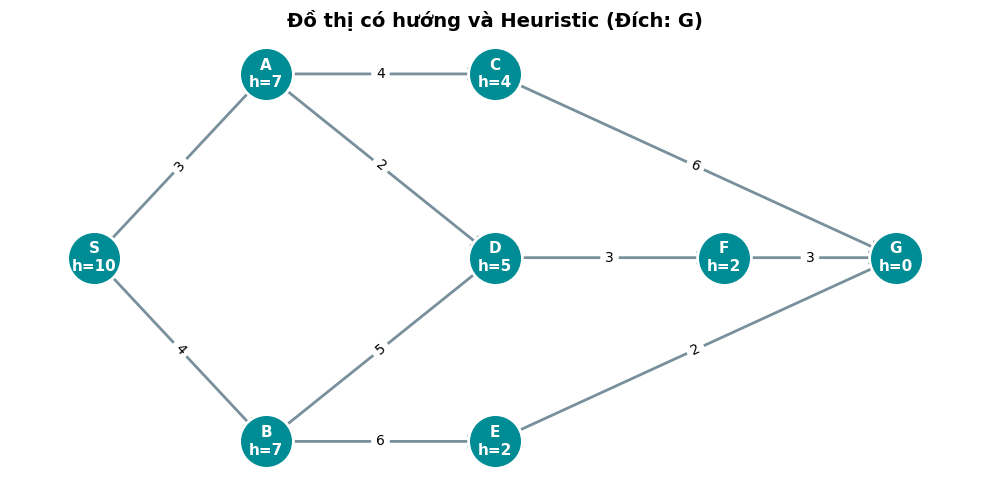

In [49]:
import networkx as nx
import matplotlib.pyplot as plt

# Định nghĩa các cạnh có hướng kèm trọng số (u -> v, trọng số)
directed_edges = [
    ('S', 'A', 3), ('S', 'B', 4),
    ('A', 'C', 4), ('A', 'D', 2),
    ('B', 'D', 5), ('B', 'E', 6),
    ('C', 'G', 6), ('D', 'F', 3),
    ('E', 'G', 2), ('F', 'G', 3)
]

# Giá trị Heuristic từ các đỉnh đến đích G
heuristic_directed = {
    'S': 10, 'A': 7, 'B': 7, 'C': 4, 'D': 5, 'E': 2, 'F': 2, 'G': 0
}

# Khởi tạo đồ thị có hướng
DG = nx.DiGraph()
DG.add_weighted_edges_from(directed_edges)

# Tọa độ các đỉnh để vẽ trực quan đẹp mắt
pos_directed = {
    'S': (0, 1),
    'A': (1.5, 2), 'B': (1.5, 0),
    'C': (3.5, 2), 'D': (3.5, 1), 'E': (3.5, 0),
    'F': (5.5, 1),
    'G': (7.0, 1)
}

# Vẽ đồ thị có hướng
fig, ax = plt.subplots(figsize=(10, 5))
nx.draw_networkx_edges(DG, pos_directed, ax=ax, arrowstyle='->', arrowsize=20, edge_color='#78909C', width=2)
nx.draw_networkx_nodes(DG, pos_directed, ax=ax, node_color='#008C95', node_size=1500, edgecolors='white', linewidths=2)

labels_dir = {n: f'{n}\nh={heuristic_directed[n]}' for n in DG.nodes()}
nx.draw_networkx_labels(DG, pos_directed, ax=ax, labels=labels_dir, font_size=11, font_weight='bold', font_color='white')
nx.draw_networkx_edge_labels(DG, pos_directed, ax=ax, edge_labels={(u, v): w for u, v, w in directed_edges}, font_size=10)

ax.set_title('Đồ thị có hướng và Heuristic (Đích: G)', fontsize=14, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

```markdown
### 1. Thuật toán A* trên Đồ thị có hướng (Tìm đường đi từ S đến G)
```

In [50]:
import heapq

def astar_directed_with_steps(edges_list, h, start, goal):
    # Xây dựng danh sách kề có hướng
    adj_dir = {}
    for u, v, w in edges_list:
        if u not in adj_dir: adj_dir[u] = []
        if v not in adj_dir: adj_dir[v] = []
        adj_dir[u].append((v, w))

    counter = 0
    heap = [(h[start], 0, counter, start)]
    open_nodes = {start}
    closed = set()
    parent = {start: None}
    g_score = {start: 0}
    steps = []

    while heap:
        f, g_cost, _, current = heapq.heappop(heap)
        if current in closed or g_cost != g_score.get(current):
            continue
        open_nodes.discard(current)
        closed.add(current)
        newly_discovered = []

        if current != goal and current in adj_dir:
            for neighbor, weight in adj_dir[current]:
                tentative_g = g_cost + weight
                if tentative_g < g_score.get(neighbor, float('inf')):
                    is_new = neighbor not in g_score
                    g_score[neighbor] = tentative_g
                    parent[neighbor] = current
                    counter += 1
                    heapq.heappush(heap, (tentative_g + h[neighbor], tentative_g, counter, neighbor))
                    open_nodes.add(neighbor)
                    if is_new:
                        newly_discovered.append(neighbor)

        open_display = sorted(open_nodes, key=lambda n: (g_score[n] + h[n], n))
        steps.append({
            'current': current, 'open': open_display, 'visited': set(closed),
            'parent': dict(parent), 'g_score': dict(g_score),
            'newly_discovered': newly_discovered, 'found': current == goal,
            'g': g_cost, 'h': h[current], 'f': g_cost + h[current]
        })
        if current == goal:
            break

    path = []
    if goal in parent:
        node = goal
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    return path, g_score.get(goal, float('inf')), steps, adj_dir

dir_path, dir_cost, dir_steps, adj_dir = astar_directed_with_steps(
    directed_edges, heuristic_directed, 'S', 'G'
)
print('Đường đi tìm thấy:', ' → '.join(dir_path))
print('Tổng chi phí tối ưu:', dir_cost)

Đường đi tìm thấy: S → A → D → F → G
Tổng chi phí tối ưu: 11


```markdown
### 2. Hàm vẽ đồ thị động cập nhật trạng thái có hướng
```

In [51]:
def draw_directed_graph(ax, current=None, visited=None, queue=None, path=None, title='A* Directed Search'):
    visited = set() if visited is None else set(visited)
    queue = [] if queue is None else list(queue)
    path = [] if path is None else list(path)
    path_edges = {(path[i], path[i+1]) for i in range(len(path)-1)}

    colors = []
    for node in DG.nodes():
        if node == current:
            colors.append('#FF9800')  # Đang xét
        elif node in path:
            colors.append('#00C853')  # Đường đi cuối
        elif node in visited:
            colors.append('#90CAF9')  # Đã mở rộng (Closed)
        elif node in queue:
            colors.append('#FFF176')  # Đang ở OPEN
        else:
            colors.append('#008C95')

    edge_colors = ['#E53935' if e in path_edges else '#78909C' for e in DG.edges()]
    edge_widths = [3.5 if e in path_edges else 2 for e in DG.edges()]

    nx.draw_networkx_edges(DG, pos_directed, ax=ax, arrowstyle='->', arrowsize=20, edge_color=edge_colors, width=edge_widths)
    nx.draw_networkx_nodes(DG, pos_directed, ax=ax, node_color=colors, node_size=1500, edgecolors='white', linewidths=2)

    labels = {n: f'{n}\nh={heuristic_directed[n]}' for n in DG.nodes()}
    nx.draw_networkx_labels(DG, pos_directed, ax=ax, labels=labels, font_size=11, font_weight='bold', font_color='white')
    nx.draw_networkx_edge_labels(DG, pos_directed, ax=ax, edge_labels={(u, v): w for u, v, w in directed_edges}, font_size=10)

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

```markdown
### 3. Vẽ đồ thị từng bước tìm kiếm tĩnh
```

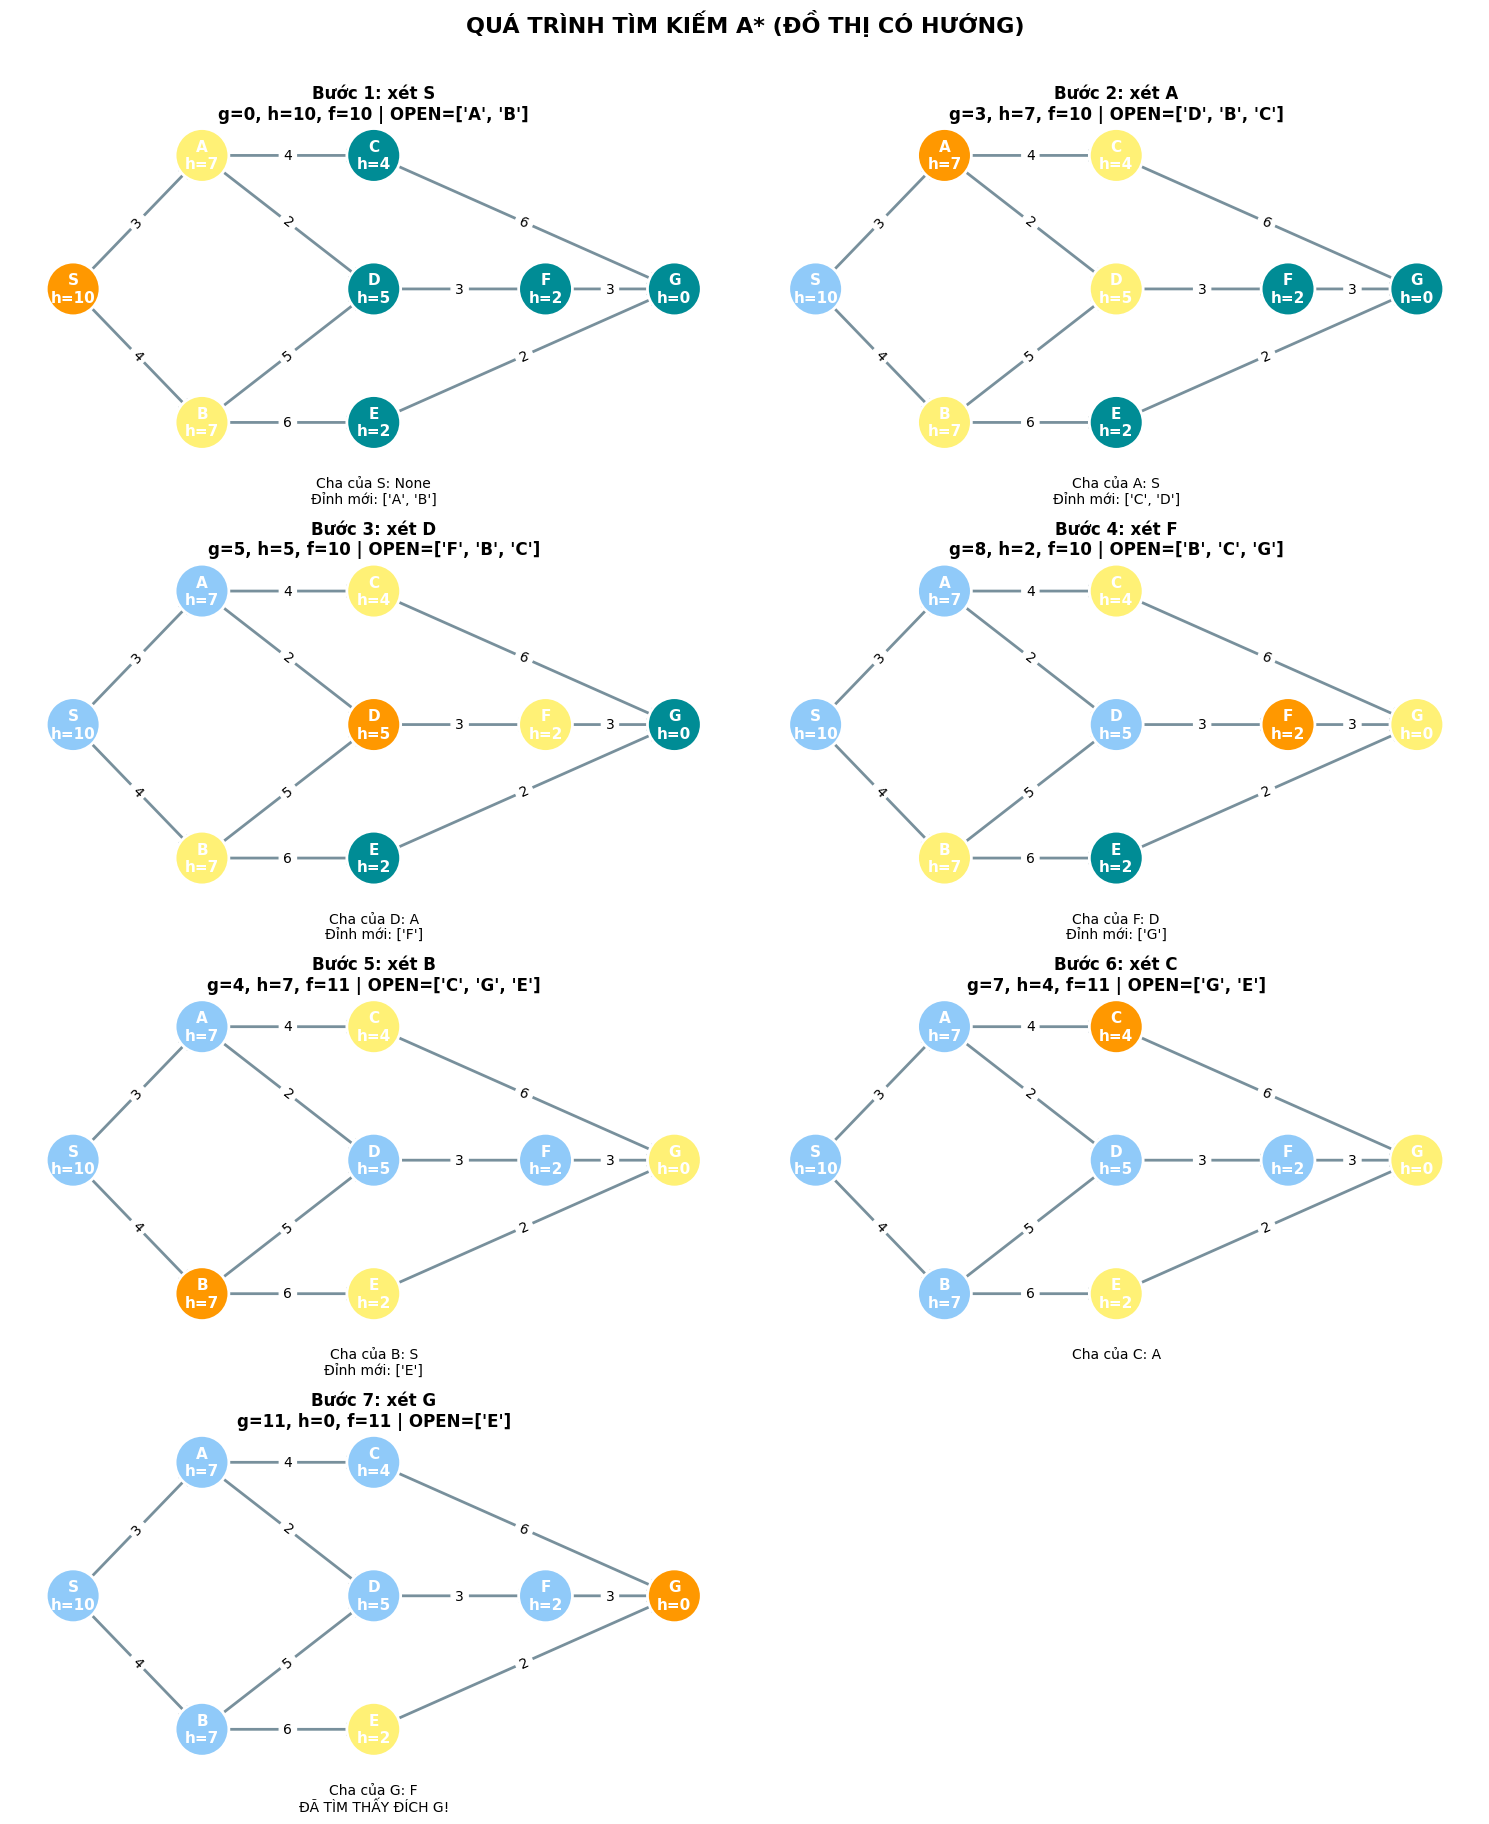

In [52]:
n_steps = len(dir_steps)
ncols = 2
nrows = (n_steps + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = axes.flatten()

for i, step in enumerate(dir_steps):
    current = step['current']
    title = f"Bước {i + 1}: xét {current}\ng={step['g']}, h={step['h']}, f={step['f']} | OPEN={step['open']}"
    draw_directed_graph(axes[i], current=current, visited=step['visited'], queue=step['open'], title=title)
    info = f"Cha của {current}: {step['parent'].get(current)}"
    if step['newly_discovered']:
        info += f"\nĐỉnh mới: {step['newly_discovered']}"
    if step['found']:
        info += '\nĐÃ TÌM THẤY ĐÍCH G!'
    axes[i].text(0.5, -0.08, info, transform=axes[i].transAxes, ha='center', va='top', fontsize=10)

for i in range(n_steps, len(axes)):
    axes[i].axis('off')
plt.suptitle('QUÁ TRÌNH TÌM KIẾM A* (ĐỒ THỊ CÓ HƯỚNG)', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

```markdown
### 4. Bảng vết thuật toán A* (Có hướng)
```

In [53]:
print('=' * 104)
print(f"{'BƯỚC':<7}{'ĐỈNH XÉT':<12}{'g':<7}{'h':<7}{'f=g+h':<9}{'OPEN sau xử lý':<30}{'ĐỈNH MỚI'}")
print('=' * 104)
for i, step in enumerate(dir_steps, start=1):
    print(f"{i:<7}{step['current']:<12}{step['g']:<7}{step['h']:<7}{step['f']:<9}"
          f"{str(step['open']):<30}{step['newly_discovered']}")
print('=' * 104)
print('Đường đi A*:', ' → '.join(dir_path))
print('Tổng trọng số tối ưu:', dir_cost)

BƯỚC   ĐỈNH XÉT    g      h      f=g+h    OPEN sau xử lý                ĐỈNH MỚI
1      S           0      10     10       ['A', 'B']                    ['A', 'B']
2      A           3      7      10       ['D', 'B', 'C']               ['C', 'D']
3      D           5      5      10       ['F', 'B', 'C']               ['F']
4      F           8      2      10       ['B', 'C', 'G']               ['G']
5      B           4      7      11       ['C', 'G', 'E']               ['E']
6      C           7      4      11       ['G', 'E']                    []
7      G           11     0      11       ['E']                         []
Đường đi A*: S → A → D → F → G
Tổng trọng số tối ưu: 11


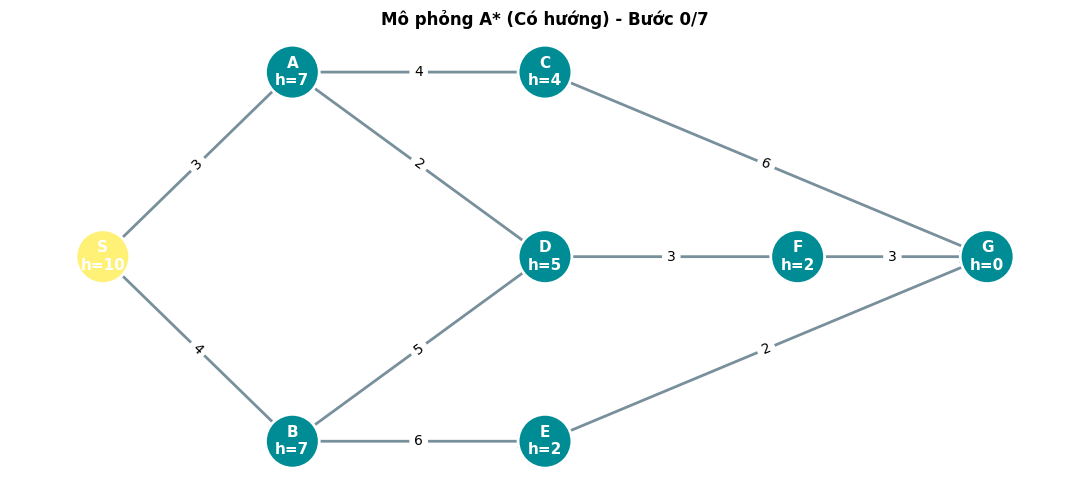

MÔ TẢ: Khởi tạo: đưa S vào OPEN với f(S)=g(S)+h(S).
Đỉnh đang xét: Chưa xét
OPEN: ['S']
Đã mở rộng (Closed): []


In [54]:
import ipywidgets as widgets
from IPython.display import clear_output
import asyncio

dir_simulation = [{
    'current': None, 'open': ['S'], 'visited': set(), 'parent': {'S': None},
    'g_score': {'S': 0}, 'newly_discovered': [], 'found': False,
    'g': 0, 'h': heuristic_directed['S'], 'f': heuristic_directed['S'],
    'message': 'Khởi tạo: đưa S vào OPEN với f(S)=g(S)+h(S).'
}]
for s in dir_steps:
    dir_simulation.append({**s, 'message':
        f"Xét {s['current']}: g={s['g']}, h={s['h']}, f={s['f']}. "
        f"Phát hiện thêm: {s['newly_discovered'] or 'không có'}."})

sim_index = 0
sim_busy = False

btn_prev = widgets.Button(description='◀ Bước trước', layout=widgets.Layout(width='125px'))
btn_next = widgets.Button(description='Bước tiếp ▶', button_style='primary', layout=widgets.Layout(width='125px'))
btn_play = widgets.Button(description='▶ Chạy tự động', button_style='success', layout=widgets.Layout(width='145px'))
btn_reset = widgets.Button(description='↺ Đặt lại', button_style='warning', layout=widgets.Layout(width='110px'))
slider = widgets.IntSlider(value=0, min=0, max=len(dir_simulation)-1, step=1,
                           description='Bước:', continuous_update=False, layout=widgets.Layout(width='95%'))
output = widgets.Output()

def show_dir_step(index):
    global sim_index, sim_busy
    if sim_busy: return
    sim_busy = True
    try:
        sim_index = max(0, min(index, len(dir_simulation)-1))
        s = dir_simulation[sim_index]
        with output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(11, 5))
            draw_directed_graph(ax, current=s['current'], visited=s['visited'], queue=s['open'],
                                path=dir_path if s['found'] else [],
                                title=f"Mô phỏng A* (Có hướng) - Bước {sim_index}/{len(dir_simulation)-1}")
            plt.tight_layout(); plt.show(); plt.close(fig)
            print('MÔ TẢ:', s['message'])
            print('Đỉnh đang xét:', s['current'] if s['current'] else 'Chưa xét')
            print('OPEN:', s['open'])
            print('Đã mở rộng (Closed):', sorted(s['visited']))
            if s['found']:
                print('ĐÃ TÌM THẤY ĐÍCH G!')
                print('Đường đi:', ' → '.join(dir_path))
        if slider.value != sim_index:
            slider.value = sim_index
    finally:
        sim_busy = False

def on_slider(change):
    if change['name'] == 'value' and not sim_busy:
        show_dir_step(change['new'])

def on_prev(_): show_dir_step(sim_index - 1)
def on_next(_): show_dir_step(sim_index + 1)
def on_reset(_): show_dir_step(0)

async def auto_play(_):
    btn_play.disabled = True
    try:
        for i in range(sim_index + 1, len(dir_simulation)):
            show_dir_step(i)
            await asyncio.sleep(1.0)
    finally:
        btn_play.disabled = False

btn_prev.on_click(on_prev)
btn_next.on_click(on_next)
btn_reset.on_click(on_reset)
btn_play.on_click(auto_play)
slider.observe(on_slider, names='value')

display(widgets.VBox([
    widgets.HTML('<h3>Mô phỏng thuật toán A* trên đồ thị có hướng</h3><p>Cam: đang xét | Xanh nhạt: đã duyệt | Vàng: trong OPEN | Xanh lá: đường đi tối ưu.</p>'),
    widgets.HBox([btn_prev, btn_next, btn_play, btn_reset]), slider, output
]))
show_dir_step(0)

```markdown
### 5. Bộ mô phỏng tìm kiếm A* trực quan tương tác nâng cao
```

```markdown
## GIẢI THÍCH CHI TIẾT BÀI TOÁN A* TRÊN ĐỒ THỊ CÓ HƯỚNG

### 1. Cấu trúc Đồ thị có hướng (Directed Graph)
Khác với đồ thị vô hướng ở bài trước, ở đây các liên kết giữa các đỉnh là **một chiều** (có hướng chỉ từ $u \rightarrow v$).
* Đỉnh bắt đầu: **S** (Source)
* Đỉnh đích cần tìm: **G** (Goal)

### 2. Hàm Heuristic $h(n)$
Hàm Heuristic $h(n)$ lưu trữ khoảng cách ước lượng từ đỉnh hiện tại $n$ đến đích **G** (ở đây $h(G) = 0$). Các giá trị cụ thể được gán cho từng đỉnh:
* $h(S) = 10$, $h(A) = 7$, $h(B) = 7$, $h(C) = 4$, $h(D) = 5$, $h(E) = 2$, $h(F) = 2$, $h(G) = 0$

### 3. Nguyên lý hoạt động của giải thuật A*
Tại mỗi bước, thuật toán sẽ chọn đỉnh $n$ trong danh sách chờ duyệt (**OPEN**) có giá trị hàm đánh giá $f(n)$ thấp nhất:
$$f(n) = g(n) + h(n)$$
Trong đó:
* $g(n)$: Chi phí thực tế đã đi từ đỉnh bắt đầu **S** đến đỉnh hiện tại $n$.
* $h(n)$: Chi phí ước lượng từ $n$ đến đích **G**.

### 4. Phân tích Quá trình Tìm kiếm Từng bước (Trace)
* **Bước 1:** Xét **S** ($g=0, f=10$). Phát hiện hai đỉnh kề hướng đi là **A** và **B** đưa vào **OPEN**:
  * Đỉnh **A**: $g(A) = 3, f(A) = 3 + 7 = 10$
  * Đỉnh **B**: $g(B) = 4, f(B) = 4 + 7 = 11$
* **Bước 2:** Đỉnh **A** có $f$ nhỏ hơn ($10 < 11$) nên được xét trước. Từ **A** đi tiếp đến **C** và **D**:
  * Đỉnh **C**: $g(C) = 3 + 4 = 7, f(C) = 7 + 4 = 11$
  * Đỉnh **D**: $g(D) = 3 + 2 = 5, f(D) = 5 + 5 = 10$
* **Bước 3:** Đỉnh **D** được chọn vì $f(D) = 10$ nhỏ nhất. Từ **D** đi tiếp đến **F**:
  * Đỉnh **F**: $g(F) = 5 + 3 = 8, f(F) = 8 + 2 = 10$
* **Bước 4:** Đỉnh **F** được chọn ($f=10$). Từ **F** đi tiếp đến đích **G**:
  * Đỉnh **G**: $g(G) = 8 + 3 = 11, f(G) = 11 + 0 = 11$
* **Các bước tiếp theo:** Lần lượt các đỉnh còn lại trong OPEN như **B**, **C** được lấy ra xét, nhưng chi phí của chúng không tối ưu hơn con đường hiện tại hoặc thuật toán dừng lại khi lấy đích **G** ra khỏi tập OPEN ở Bước 7.

**Kết quả đường đi tối ưu thu được:**
$$\mathbf{S \rightarrow A \rightarrow D \rightarrow F \rightarrow G} \quad \text{với tổng trọng số} \quad g(G) = 11$$
```